In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Importación de la función BiAA matricial/tensorial mxnx1
from src.Robusted_mxnx1_biAA import robust_biarchetypal_analysis_mxnx1
from src.biaa import biarchetypal_analysis

np.set_printoptions(precision=4, suppress=True)

In [2]:
# -------------------------------------------------------------------------
# 1. GENERACIÓN DE DATOS SINTÉTICOS Y OUTLIERS PARA BiAA
# -------------------------------------------------------------------------
rng = np.random.default_rng(42)

# Definimos dimensiones (N filas x M columnas)
N_samples, M_features = 50, 40
k_row_archetypes = 3     # Número de arquetipos por filas (k)
c_col_archetypes = 3     # Número de arquetipos por columnas (c)

# 1. Matriz de arquetipos latentes Z de dimensión (k, c)
true_Z = rng.uniform(low=0.1, high=0.9, size=(k_row_archetypes, c_col_archetypes))

# 2. Coeficientes Dirichlet para mezcla de filas (alpha: N x k) y columnas (gamma: c x M)
true_alpha = rng.dirichlet(np.ones(k_row_archetypes), size=N_samples)
true_gamma = rng.dirichlet(np.ones(c_col_archetypes), size=M_features).T

# 3. Matriz limpia reconstruida: X = alpha @ Z @ gamma
X_clean = true_alpha @ true_Z @ true_gamma

# 4. Inyección de contaminación (outliers extremos celda por celda)
X = X_clean.copy()
n_outliers = 15
row_idx = rng.integers(0, N_samples, size=n_outliers)
col_idx = rng.integers(0, M_features, size=n_outliers)

# Asignamos valores atípicos severos (ej. celda contaminada con valor 15.0)
for r, c_idx in zip(row_idx, col_idx):
    X[r, c_idx] += rng.uniform(12.0, 15.0)

print("--- INFORMACIÓN DE LOS DATOS ---")
print(f"Dimensiones de X: {X.shape}")
print(f"Arquetipos por filas (k): {k_row_archetypes} | Arquetipos por columnas (c): {c_col_archetypes}")
print(f"Celdas totales: {N_samples * M_features} | Celdas contaminadas manualmente: {n_outliers}")


--- INFORMACIÓN DE LOS DATOS ---
Dimensiones de X: (50, 40)
Arquetipos por filas (k): 3 | Arquetipos por columnas (c): 3
Celdas totales: 2000 | Celdas contaminadas manualmente: 15


In [3]:
# -------------------------------------------------------------------------
# 2. EJECUCIÓN DE ROBUST_BIARCHETYPAL_ANALYSIS_MXNX1
# -------------------------------------------------------------------------
print("\nEjecutando Robust BiAA (Bisquare M-estimator) mxnx1...")

alpha_rob, beta_rob, gamma_rob, theta_rob, Z_rob, W_mat_rob = robust_biarchetypal_analysis_mxnx1(
    X, 
    k=k_row_archetypes, 
    c=c_col_archetypes, 
    max_robust_iter=20, 
    max_inner_iter=50, 
    c_factor=6.0,       # Umbral Bisquare de corte para residuos
    tol=1e-5, 
    w_init = None,
    random_state=42, 
    verbose=True
)


Ejecutando Robust BiAA (Bisquare M-estimator) mxnx1...
Iteración Robust 1/20 | Dif. pesos: 0.114598 | Celdas Outliers (w=0): 15/2000 (0.75%)
Iteración Robust 2/20 | Dif. pesos: 0.082006 | Celdas Outliers (w=0): 15/2000 (0.75%)
Iteración Robust 3/20 | Dif. pesos: 0.009883 | Celdas Outliers (w=0): 15/2000 (0.75%)
Iteración Robust 4/20 | Dif. pesos: 0.001193 | Celdas Outliers (w=0): 15/2000 (0.75%)
Iteración Robust 5/20 | Dif. pesos: 0.001262 | Celdas Outliers (w=0): 15/2000 (0.75%)
Iteración Robust 6/20 | Dif. pesos: 0.001117 | Celdas Outliers (w=0): 15/2000 (0.75%)
Iteración Robust 7/20 | Dif. pesos: 0.000645 | Celdas Outliers (w=0): 15/2000 (0.75%)
Iteración Robust 8/20 | Dif. pesos: 0.000384 | Celdas Outliers (w=0): 15/2000 (0.75%)
Iteración Robust 9/20 | Dif. pesos: 0.000272 | Celdas Outliers (w=0): 15/2000 (0.75%)
Iteración Robust 10/20 | Dif. pesos: 0.000186 | Celdas Outliers (w=0): 15/2000 (0.75%)
Iteración Robust 11/20 | Dif. pesos: 0.000117 | Celdas Outliers (w=0): 15/2000 (0.7

In [4]:
# -------------------------------------------------------------------------
# 3. VERIFICACIÓN DE ESTRUCTURA Y MÉTRICAS DE EVALUACIÓN
# -------------------------------------------------------------------------
# Reconstrucción de la matriz aproximada X_hat
X_hat_rob = alpha_rob @ Z_rob @ gamma_rob

# Funciones de cálculo de error
def sse(X_true, X_reconstructed):
    return float(np.sum((X_true - X_reconstructed) ** 2))

def weighted_sse(X_true, X_reconstructed, W):
    if W.ndim == 3:
        W = W.squeeze(axis=-1)
    return float(np.sum(W * ((X_true - X_reconstructed) ** 2)))

sse_total = sse(X, X_hat_rob)
sse_ponderado = weighted_sse(X, X_hat_rob, W_mat_rob)
outliers_detectados = np.sum(W_mat_rob == 0.0)

print("\n--- RESULTADOS Y VERIFICACIÓN DE DIMENSIONES ---")
print(f"Dim de Alpha (N x k): {alpha_rob.shape}")
print(f"Dim de Gamma (c x M): {gamma_rob.shape}")
print(f"Dim de Z (k x c):     {Z_rob.shape}")
print(f"Dim de W_mat:         {W_mat_rob.shape}")

# Creación de DataFrame cuantitativo
df_results = pd.DataFrame([{
    "Método": "Robusted_mxnx1_biAA (Bisquare)",
    "Outliers (w=0)": f"{outliers_detectados} / {N_samples * M_features}",
    "SSE Original (Total)": sse_total,
    "SSE Ponderado (Robusto)": sse_ponderado
}])

print(df_results.round(4))


--- RESULTADOS Y VERIFICACIÓN DE DIMENSIONES ---
Dim de Alpha (N x k): (50, 3)
Dim de Gamma (c x M): (3, 40)
Dim de Z (k x c):     (3, 3)
Dim de W_mat:         (50, 40)
                           Método Outliers (w=0)  SSE Original (Total)  \
0  Robusted_mxnx1_biAA (Bisquare)      15 / 2000             2788.7676   

   SSE Ponderado (Robusto)  
0                  10.6305  


In [5]:
# --- PAS 1: Aplicar BiAA estándar a X ---
alpha_std, beta_std, gamma_std, theta_std, Z_std, _ = biarchetypal_analysis(
    X_clean, 
    k=k_row_archetypes, 
    c=c_col_archetypes, 
    max_iter=200, 
    tol=1e-5, 
    seed=42, 
    verbose=False
)

print("--- RESULTADO PAS 1: Z biaa (Afectado por Outliers) ---")
print(Z_std.round(4))

# Cálculo de residuos absolutos para evidenciar dónde están los outliers en X
residuos_abs = np.abs(X - (alpha_std @ Z_std @ gamma_std))
print(f"\nResiduos máximos detectados en X: {np.max(residuos_abs):.4f}")

print("--- COMPARACIÓN FINAL (IDEAL DEL PROFESOR) ---")
print("\n1. Matriz original (true_Z):")
print(true_Z.round(4))

print("\n2. Matriz estimada robusta (Z_rob - sin outliers):")
print(Z_rob.round(4))

# Verificamos qué tan parecidas son
error_robusto = np.mean(np.abs(true_Z - Z_rob))
print(f"\nDiferencia media entre true_Z y Z_rob: {error_robusto:.4f} (¡Debe ser muy cercana a 0!)")

--- RESULTADO PAS 1: Z biaa (Afectado por Outliers) ---
[[0.5952 0.5841 0.5968]
 [0.5943 0.5833 0.5959]
 [0.5978 0.5863 0.5995]]

Residuos máximos detectados en X: 14.5357
--- COMPARACIÓN FINAL (IDEAL DEL PROFESOR) ---

1. Matriz original (true_Z):
[[0.7192 0.4511 0.7869]
 [0.6579 0.1753 0.8805]
 [0.7089 0.7289 0.2025]]

2. Matriz estimada robusta (Z_rob - sin outliers):
[[0.5565 0.5536 0.5591]
 [0.5574 0.5535 0.5596]
 [0.56   0.5543 0.5616]]

Diferencia media entre true_Z y Z_rob: 0.2194 (¡Debe ser muy cercana a 0!)


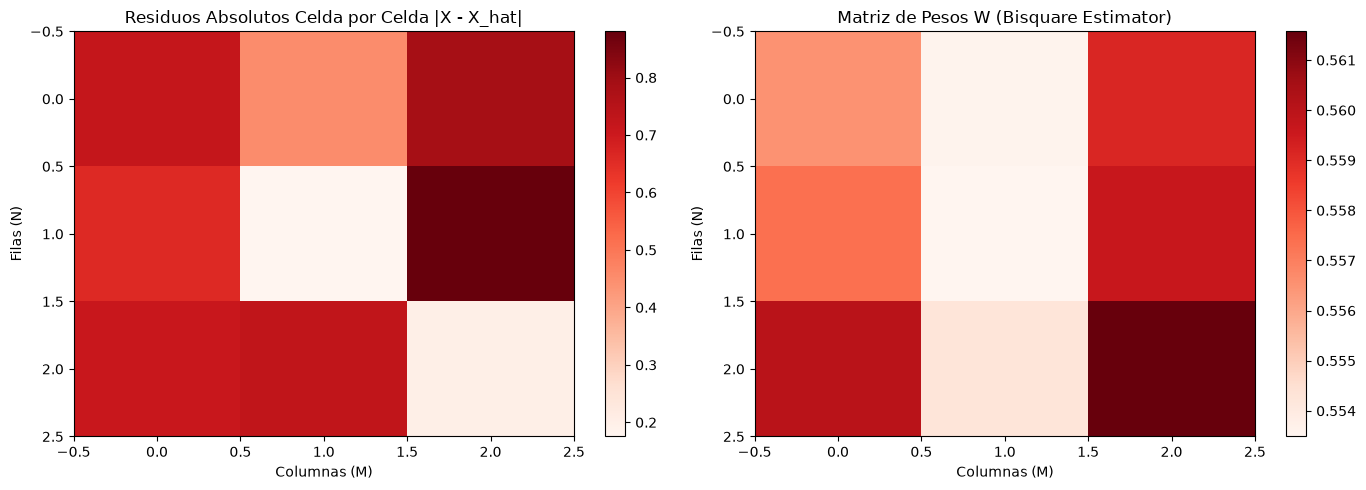

In [6]:
# -------------------------------------------------------------------------
# 4. VISUALIZACIÓN DE MATRIZ DE PESOS (DETECCIÓN DE OUTLIERS)
# -------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Calor de la matriz de residuos absolutos
residuos_abs = np.abs(X - X_hat_rob)
im0 = axes[0].imshow(true_Z, aspect='auto', cmap='Reds')
axes[0].set_title("Residuos Absolutos Celda por Celda |X - X_hat|")
axes[0].set_xlabel("Columnas (M)")
axes[0].set_ylabel("Filas (N)")
plt.colorbar(im0, ax=axes[0])

# Calor de los pesos Bisquare W obtenidos
im1 = axes[1].imshow(Z_rob, aspect='auto', cmap='Reds')
axes[1].set_title("Matriz de Pesos W (Bisquare Estimator)")
axes[1].set_xlabel("Columnas (M)")
axes[1].set_ylabel("Filas (N)")
plt.colorbar(im1, ax=axes[1])

plt.tight_layout()
plt.show()

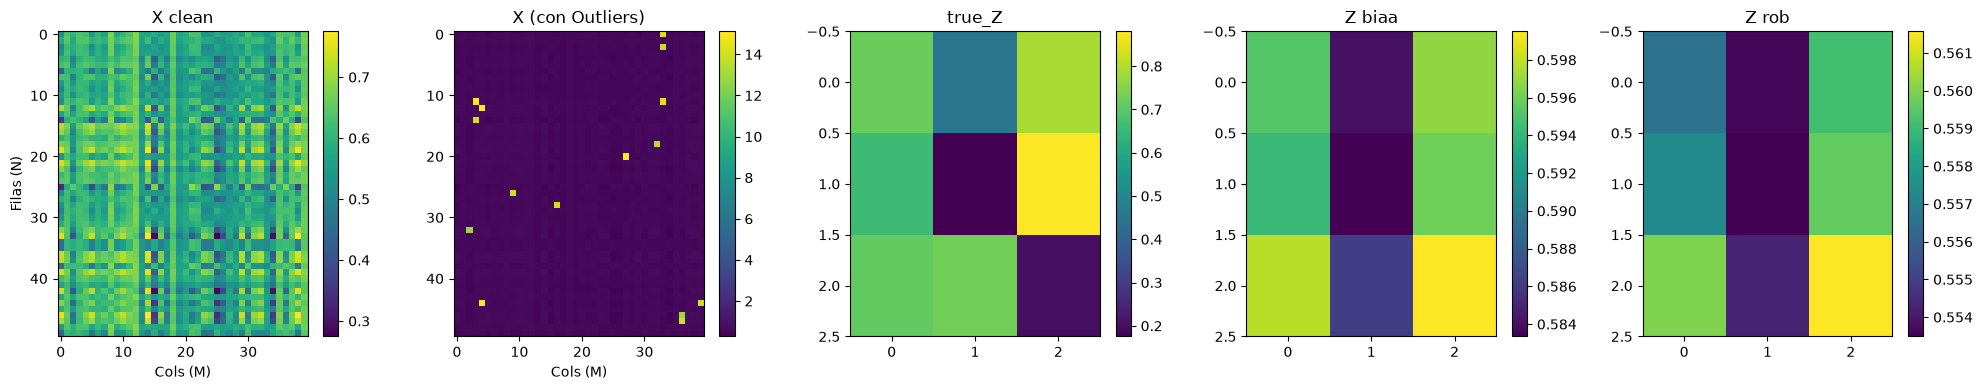

In [7]:
# -------------------------------------------------------------------------
# COMPARACIÓN VISUAL COMPLETA (Esquema completo del profesor)
# -------------------------------------------------------------------------
fig, axes = plt.subplots(1, 5, figsize=(20, 4))

# 1. X_clean (Datos limpios originales)
im0 = axes[0].imshow(X_clean, aspect='auto', cmap='viridis')
axes[0].set_title("X clean")
axes[0].set_xlabel("Cols (M)")
axes[0].set_ylabel("Filas (N)")
fig.colorbar(im0, ax=axes[0])

# 2. X (Datos con outliers inyectados)
im1 = axes[1].imshow(X, aspect='auto', cmap='viridis')
axes[1].set_title("X (con Outliers)")
axes[1].set_xlabel("Cols (M)")
fig.colorbar(im1, ax=axes[1])

# 3. True Z (La matriz de arquetipos limpia ideal)
im2 = axes[2].imshow(true_Z, aspect='auto', cmap='viridis')
axes[2].set_title("true_Z")
fig.colorbar(im2, ax=axes[2])

# 4. Z BiAA Estándar (Afectada por la contaminación)
im3 = axes[3].imshow(Z_std, aspect='auto', cmap='viridis')
axes[3].set_title("Z biaa")
fig.colorbar(im3, ax=axes[3])

# 5. Z Robusto (Recuperada tras aplicar Robust BiAA)
im4 = axes[4].imshow(Z_rob, aspect='auto', cmap='viridis')
axes[4].set_title("Z rob")
fig.colorbar(im4, ax=axes[4])

plt.tight_layout()
plt.show()